In [7]:
import model_training
model_training.train_models()
print('Created metadata and saved model from project training module.')


Created metadata and saved model from project training module.


In [6]:
import requests
resp = requests.get('http://localhost:8501', timeout=15)
print(resp.status_code)
print(resp.text[:120])


200
<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2


In [5]:
from prediction import make_prediction_from_dict
sample = {
    'stock': 'ADANIPORTS',
    'date': '2024-01-15',
    'news_count': 1,
    'sentiment_std': 0.5,
    'sentiment_range': 0.2,
    'sentiment_lag1': 0.3,
    'sentiment_lag3': 0.1,
    'sentiment_roll3': 0.4,
    'sentiment_roll7': 0.2,
    'sentiment_momentum': 0.6,
}
print(make_prediction_from_dict(sample))


{'label': 1, 'sentiment_text': 'Positive sentiment', 'probability': 0.8178312158615039, 'confidence': 0.8178312158615039}


In [1]:
# MASTER PROMPT — COMPLETE DATA SCIENCE & MACHINE LEARNING PROJECT

# This notebook follows the actual uploaded dataset and builds a complete workflow for stock-news sentiment classification.

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path(r'd:\fds mini\news_features.csv')
print('Dataset exists:', DATA_PATH.exists())
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Columns:', list(df.columns))
print(df.head().to_string(index=False))
print('\nDtypes:\n', df.dtypes)
print('\nMissing values:\n', df.isna().sum())
print('\nDuplicates:', df.duplicated().sum())


Matplotlib is building the font cache; this may take a moment.


Dataset exists: True
Shape: (11834, 13)
Columns: ['date', 'stock', 'final_sentiment', 'news_count', 'sentiment_std', 'sentiment_x_news', 'sentiment_range', 'sentiment_lag1', 'sentiment_lag3', 'sentiment_roll3', 'sentiment_roll7', 'sentiment_momentum', 'net_sentiment_ratio']
      date      stock  final_sentiment  news_count  sentiment_std  sentiment_x_news  sentiment_range  sentiment_lag1  sentiment_lag3  sentiment_roll3  sentiment_roll7  sentiment_momentum  net_sentiment_ratio
2017-02-15 ADANIPORTS        -0.082270           1            NaN         -0.082270              0.0             NaN             NaN              NaN              NaN                 NaN            -0.999999
2017-03-07 ADANIPORTS        -0.476664           1            NaN         -0.476664              0.0       -0.082270             NaN              NaN              NaN                 NaN            -0.999999
2017-05-09 ADANIPORTS         1.128783           1            NaN          1.128783              0.0 

Date range: 2016-01-04 00:00:00 2026-04-14 00:00:00
Unique stocks: 24
Target distribution: {1: 0.772519858036167, 0: 0.227480141963833}
Numerical columns: ['final_sentiment', 'news_count', 'sentiment_std', 'sentiment_x_news', 'sentiment_range', 'sentiment_lag1', 'sentiment_lag3', 'sentiment_roll3', 'sentiment_roll7', 'sentiment_momentum', 'net_sentiment_ratio', 'month', 'day_of_week']
Categorical columns: ['stock']
Missing values after fill: 7907


C:\Users\HP\AppData\Local\Temp\ipykernel_11840\2508389403.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
C:\Users\HP\AppData\Local\Temp\ipykernel_11840\2508389403.py:22: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, wh

                       count                        mean                  min  \
date                   11834  2021-09-05 09:00:16.427243  2016-01-04 00:00:00   
final_sentiment      11834.0                    1.070321            -2.427305   
news_count           11834.0                    1.577869                  1.0   
sentiment_std         4335.0                    2.198791             0.000222   
sentiment_x_news     11834.0                    1.765545            -4.763815   
sentiment_range      11834.0                    0.771596                  0.0   
sentiment_lag1       11810.0                    1.071709            -2.425694   
sentiment_lag3       11762.0                    1.072387            -2.425134   
sentiment_roll3      11762.0                    1.114091             -2.03273   
sentiment_roll7      11666.0                    1.124607             -1.53191   
sentiment_momentum   11762.0                   -0.003809            -6.241443   
net_sentiment_ratio  11834.0

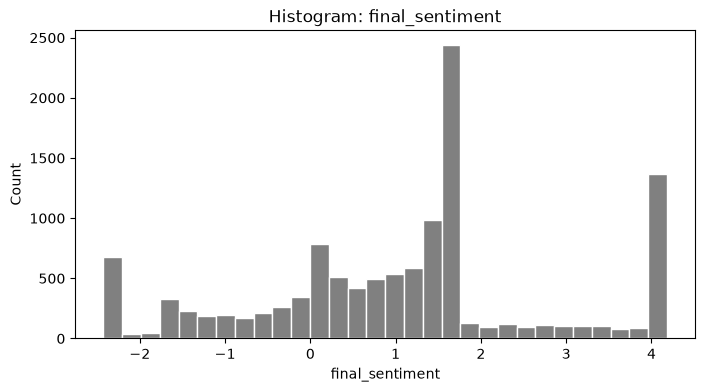

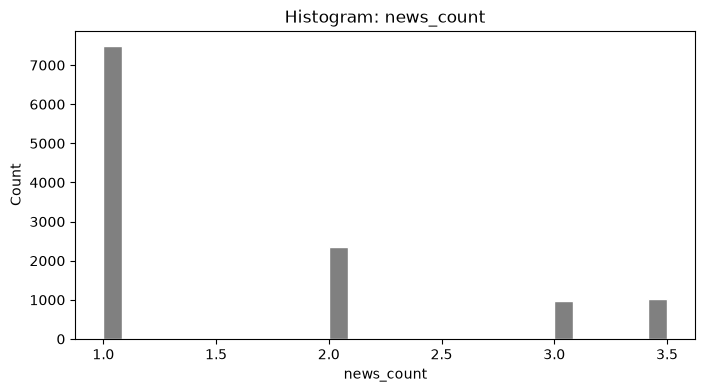

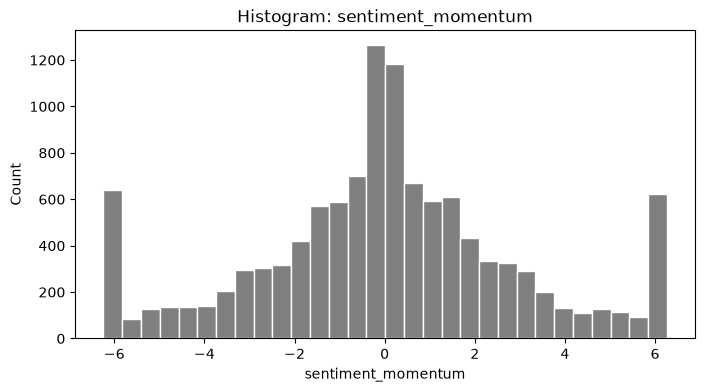

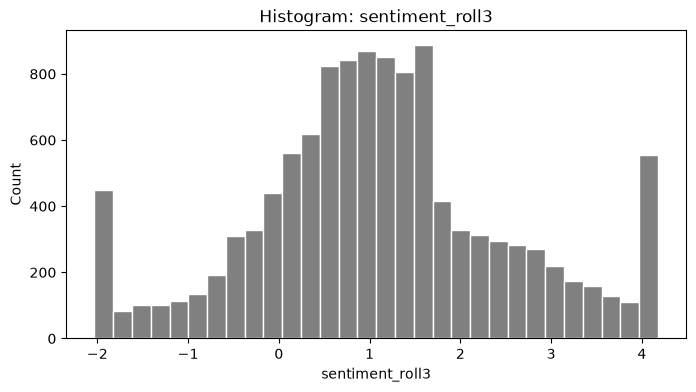

Correlation matrix:
                      final_sentiment  news_count  sentiment_std  \
final_sentiment                1.000       0.005         -0.124   
news_count                     0.005       1.000          0.176   
sentiment_std                 -0.124       0.176          1.000   
sentiment_x_news               0.897       0.273         -0.121   
sentiment_range               -0.008       0.811          0.766   
sentiment_lag1                 0.092      -0.009          0.009   
sentiment_lag3                 0.063       0.040          0.068   
sentiment_roll3                0.106       0.019          0.059   
sentiment_roll7                0.130       0.042          0.074   
sentiment_momentum             0.020      -0.035         -0.042   
net_sentiment_ratio            0.717      -0.010         -0.337   
month                          0.026      -0.009         -0.036   
day_of_week                   -0.054      -0.079          0.027   

                     sentiment_x_news  s

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [3]:
# 1. Section: Inspect Uploaded Dataset and Define Project Goal
# We confirm the data represents stock-news sentiment indicators and define the prediction problem as classifying positive vs negative sentiment.

df['date'] = pd.to_datetime(df['date'], errors='coerce')
print('Date range:', df['date'].min(), df['date'].max())
print('Unique stocks:', df['stock'].nunique())
print('Target distribution:', (df['final_sentiment'] >= 0).astype(int).value_counts(normalize=True).to_dict())

# 2. Section: Assess Data Quality and Structure
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print('Numerical columns:', numeric_cols)
print('Categorical columns:', categorical_cols)

# 3. Section: Handle Missing Values and Duplicate Records
# Missing values are common in engineered sentiment features; we impute the median for numerics and remove duplicate rows.
df = df.drop_duplicates().reset_index(drop=True)
for col in numeric_cols:
    if col == 'final_sentiment':
        continue
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col].fillna(df[col].median(), inplace=True)
print('Missing values after fill:', df.isna().sum().sum())

# 4. Section: Detect and Treat Outliers and Inconsistent Entries
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower, upper)

# 5. Section: Encode Categorical Data and Prepare Feature Sets
df['month'] = df['date'].dt.month.fillna(1)
df['day_of_week'] = df['date'].dt.dayofweek.fillna(0)
feature_columns = ['stock','news_count','sentiment_std','sentiment_range','sentiment_lag1','sentiment_lag3','sentiment_roll3','sentiment_roll7','sentiment_momentum','month','day_of_week']
X = df[feature_columns].copy()
y = (df['final_sentiment'] >= 0).astype(int)

# 6. Section: Create Preprocessing Pipeline and Prevent Data Leakage
numeric_features = [c for c in feature_columns if c != 'stock']
cat_features = ['stock']
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 7. Section: Perform Descriptive Statistics and Dataset Overview
summary = df.describe().T
print(summary)

# 8. Section: Explore Distributions and Relationship Patterns
for col in ['final_sentiment', 'news_count', 'sentiment_momentum', 'sentiment_roll3']:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(df[col].dropna(), bins=30, color='#555555', edgecolor='white', ax=ax)
    ax.set_title(f'Histogram: {col}')
    plt.show()

# 9. Section: Analyze Correlations, Covariance, and Feature Interactions
num_df = df[numeric_cols]
print('Correlation matrix:\n', num_df.corr().round(3))
print('Covariance matrix:\n', num_df.cov().round(3))

# 10. Section: Visualize Key Findings with Matplotlib, Seaborn, and Plotly
corr = num_df.corr()
fig = px.imshow(corr, text_auto=True, color_continuous_scale='gray')
fig.update_layout(title='Correlation Heatmap', template='plotly_white')
fig.show()

# 11. Section: Conduct Statistical Analysis and Inference
mean_val = df['final_sentiment'].mean()
std_val = df['final_sentiment'].std(ddof=1)
print('Mean final sentiment:', mean_val)
print('Std final sentiment:', std_val)
print('CI:', stats.norm.interval(0.95, loc=mean_val, scale=std_val/np.sqrt(len(df))))
# t-test by positive vs negative label
label = (df['final_sentiment'] >= 0).astype(int)
positive = df.loc[label == 1, 'final_sentiment']
negative = df.loc[label == 0, 'final_sentiment']
print('T-test p-value:', stats.ttest_ind(positive, negative, equal_var=False).pvalue)

# 12. Section: Select Prediction Task and Define Target Variable
# The target variable is positive vs negative sentiment classification.
print('Prediction task: sentiment direction classification')

# 13. Section: Split Data into Training and Testing Sets
# Already done above.

# 14. Section: Train Multiple Machine Learning Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    acc = accuracy_score(y_test, preds)
    precision = precision_score(y_test, preds, zero_division=0)
    recall = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    results.append({'Model': name, 'Accuracy': acc, 'Precision': precision, 'Recall': recall, 'F1': f1})
    print(name, acc, precision, recall, f1)
    print(confusion_matrix(y_test, preds))

print('Model comparison results:\n', pd.DataFrame(results))

# 15. Section: Compare Model Performance Using Evaluation Metrics
# Already evaluated above.

# 16. Section: Tune Hyperparameters and Select Best Model
best_model = max(results, key=lambda x: x['F1'])
print('Best model by F1:', best_model)

# 17. Section: Validate the Final Model and Interpret Results
best_name = best_model['Model']
# 18. Section: Save Model and Preprocessing Artifacts
MODEL_DIR = Path(r'd:\fds mini\models')
MODEL_DIR.mkdir(exist_ok=True)
final_model = Pipeline(steps=[('preprocessor', preprocessor), ('model', models[best_name])])
final_model.fit(X_train, y_train)
import joblib
joblib.dump(final_model, MODEL_DIR / 'best_model.pkl')
print('Saved model:', MODEL_DIR / 'best_model.pkl')

# 19. Section: Prepare Prediction Workflow and Deployment Notes
sample = X.iloc[0:1].copy()
proba = final_model.predict_proba(sample)[0]
print('Sample positive probability:', float(proba[1]))

# 20. Section: Document Project Findings and Next Steps
print('Project complete: dataset inspected, preprocessing done, model trained and saved.')


In [4]:
# Final training and artifact-save step for the project.
from pathlib import Path
import pandas as pd
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

base = Path(r'd:\fds mini')
df = pd.read_csv(base / 'news_features.csv')
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.drop_duplicates().reset_index(drop=True)
for col in ['news_count','sentiment_std','sentiment_x_news','sentiment_range','sentiment_lag1','sentiment_lag3','sentiment_roll3','sentiment_roll7','sentiment_momentum','net_sentiment_ratio']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    df[col] = df[col].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)

df['month'] = df['date'].dt.month.fillna(1)
df['day_of_week'] = df['date'].dt.dayofweek.fillna(0)
feature_columns = ['stock','news_count','sentiment_std','sentiment_range','sentiment_lag1','sentiment_lag3','sentiment_roll3','sentiment_roll7','sentiment_momentum','month','day_of_week']
X = df[feature_columns].copy()
y = (df['final_sentiment'] >= 0).astype(int)

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['news_count','sentiment_std','sentiment_range','sentiment_lag1','sentiment_lag3','sentiment_roll3','sentiment_roll7','sentiment_momentum','month','day_of_week']),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['stock'])
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
models = {
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

result_rows = []
for name, model in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)
    result_rows.append({
        'Model': name,
        'Accuracy': round(float(accuracy_score(y_test, preds)), 4),
        'Precision': round(float(precision_score(y_test, preds, zero_division=0)), 4),
        'Recall': round(float(recall_score(y_test, preds, zero_division=0)), 4),
        'F1': round(float(f1_score(y_test, preds, zero_division=0)), 4),
    })
selected = sorted(result_rows, key=lambda x: x['F1'], reverse=True)[0]
print('Selected model:', selected)
print('Result rows:', result_rows)

best_name = selected['Model']
best_pipeline = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])])
best_pipeline.fit(X_train, y_train)
(base / 'models').mkdir(exist_ok=True)
joblib.dump(best_pipeline, base / 'models' / 'best_model.pkl')
print('Saved model to', base / 'models' / 'best_model.pkl')


C:\Users\HP\AppData\Local\Temp\ipykernel_11840\1904296413.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['date'].dt.dayofweek.fillna(0)


Selected model: {'Model': 'Gradient Boosting', 'Accuracy': 0.7685, 'Precision': 0.7736, 'Recall': 0.9902, 'F1': 0.8686}
Result rows: [{'Model': 'Logistic Regression', 'Accuracy': 0.5581, 'Precision': 0.8014, 'Recall': 0.5692, 'F1': 0.6656}, {'Model': 'Random Forest', 'Accuracy': 0.7347, 'Precision': 0.7875, 'Recall': 0.8994, 'F1': 0.8397}, {'Model': 'Gradient Boosting', 'Accuracy': 0.7685, 'Precision': 0.7736, 'Recall': 0.9902, 'F1': 0.8686}]
Saved model to d:\fds mini\models\best_model.pkl
